### Top Rows

In [628]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display, HTML

def display_scroll(df, height="400px"):
    display(HTML(f"""
    <div style="max-height:{height}; overflow:auto; border:1px solid #ccc; padding:5px;">
        {df.to_html()}
    </div>
    """))
    
file_path = "results-filtered.xlsx"

# df = pd.read_excel(file_path, sheet_name="kPEX-bad-heur")
# versions="v0 v1 v2 v3".split()

df = pd.read_excel(file_path, sheet_name="kPEX")
versions="v0 v1 v2 v3 v4".split()

# df = pd.read_excel(file_path, sheet_name="UMKP+AltRB")
# versions="v0 v1 v2 v3".split()

branchings="S".split()

for v in versions: 
    df[f"{v}-prep"] = (df[f"{v}-S-bnb"] == "prep")
    cols = [f"{v}-{b}-ctcp" for b in branchings]
    df[f"{v}-ctcp"] = (
        df[cols]
        .apply(pd.to_numeric, errors="coerce")  # non-numeric → NaN
        .mean(axis=1)                           # skips NaN automatically
    )
    cols = [f"{v}-{b}-heur" for b in branchings]
    df[f"{v}-heur"] = (
        df[cols]
        .apply(pd.to_numeric, errors="coerce")  # non-numeric → NaN
        .mean(axis=1)                           # skips NaN automatically
    )    

    
def clean_dataframe(df):
    df = df.dropna(axis=1, how="all")
    df = df.copy()

    def convert_col(col):
        # replace exact matches first
        col = col.replace({"x": 1800, "prep": 0})
        
        # try numeric conversion WITHOUT destroying original values
        numeric = pd.to_numeric(col, errors="coerce")
        
        # keep original where conversion failed
        return numeric.where(~numeric.isna(), col)

    return df.apply(convert_col)

df = clean_dataframe(df)

for v in versions: 
    df[f"{v}-init"] = df[f"{v}-heur"]+df[f"{v}-ctcp"]
    df[f"{v}-prep"] = df[f"{v}-prep"].replace(False, "")
    
df.head()
pd.set_option('display.float_format', '{:.1f}'.format)
pd.set_option('display.max_rows', 50)
pd.set_option('display.max_columns', None)



# df = df[~((df["v2-S-total"] > 500) & (df["v3-S-total"] < 500) & (df["v3-init"] < 10))]
# df = df[~((df["v3-S-total"] > 500) & (df["v2-S-total"] < 500)& (df["v2-init"] < 10))]

# df = df[~((df["v0-S-total"] > 500) & (df["v3-S-total"] < 500) & (df["v3-init"] < 10))]
# df = df[~((df["v3-S-total"] > 500) & (df["v0-S-total"] < 500)& (df["v0-init"] < 10))]

# for v in versions: 
# cols = [f"v0-{b}-mkp" for b in "S R P".split() ]
# cols = [f"v{i}-{b}-mkp" for i in [0, 1] for b in "S".split() ]

# mask = df[cols].apply(lambda row: row[row != 1800].nunique() > 1, axis=1)
# display_scroll(df.loc[mask, cols+["dataset", "k", "v0-S-total", "v1-S-total"]])
# filtered_df = df[mask]

# filtered_df[["dataset", "k"]].to_excel("filtered_rows.xlsx", index=False)
# mask.sum()

/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_38912/3127737945.py:48: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  col = col.replace({"x": 1800, "prep": 0})
/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_38912/3127737945.py:48: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  col = col.replace({"x": 1800, "prep": 0})
/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_38912/3127737945.py:48: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To reta

### Varying Ratio Threshold

In [637]:
def compare_speedups(df, col_a, col_b,
                     thresholds=[1.2, 2, 4, 6, 8, 10],
                     min_time_threshold=1.0,
                     max_len=25):
    
    import matplotlib.pyplot as plt

    # =========================
    # Setup
    # =========================
    va = col_a.split("-")[0]
    vb = col_b.split("-")[0]

    # =========================
    # Handle zeros
    # =========================
    df = df.replace(0, 0.01)

    # =========================
    # Filter
    # =========================
    df_filtered = df[
        (df[col_a] >= min_time_threshold) | (df[col_b] >= min_time_threshold)
    ].copy()

    # =========================
    # Compute speedups
    # =========================
    df_filtered["speedup_a"] = df_filtered[col_b] / df_filtered[col_a]
    df_filtered["speedup_b"] = df_filtered[col_a] / df_filtered[col_b]

    # =========================
    # Threshold = first threshold
    # =========================
    threshold_check = thresholds[0]

    a_wins = df_filtered[df_filtered["speedup_a"] >= threshold_check].copy()
    b_wins = df_filtered[df_filtered["speedup_b"] >= threshold_check].copy()

    # =========================
    # Determine weaker & stronger
    # =========================
    if len(a_wins) < len(b_wins):
        weaker, stronger = "A", "B"
    elif len(b_wins) < len(a_wins):
        weaker, stronger = "B", "A"
    else:
        weaker = stronger = "Tie"

    # =========================
    # Formatting function
    # =========================
    def format_df(df_in, side):
        if side == "A":
            speedup_series = df_in["speedup_a"].map(lambda x: f"{x:.2f}x")
        else:
            speedup_series = df_in["speedup_b"].map(lambda x: f"{x:.2f}x")

        return df_in.assign(
            dataset=df_in["dataset"].apply(
                lambda x: (str(x)[:max_len] + "...") if len(str(x)) > max_len else str(x)
            ),
            speedup=speedup_series
        )[[
            "dataset", "k",
            col_a, col_b,
            "speedup",
            f"{va}-ctcp", f"{vb}-ctcp",
            f"{va}-heur", f"{vb}-heur",
            f"{va}-init", f"{vb}-init",
            f"{va}-prep", f"{vb}-prep",
            f"{va}-S-total", f"{vb}-S-total"
        ]]

    # =========================
    # Print summary
    # =========================
    print(f"\n=== Threshold {threshold_check} Analysis ===")
    print(f"{col_a} wins: {len(a_wins)}")
    print(f"{col_b} wins: {len(b_wins)}")

    # =========================
    # Display results
    # =========================
    if weaker == "Tie":
        print("Both sides have equal wins.")

        print("\n--- Side A (>= threshold) ---")
        display_scroll(format_df(a_wins.sort_values(by=col_a, ascending=False), "A"))

        print("\n--- Side B (>= threshold) ---")
        display_scroll(format_df(b_wins.sort_values(by=col_b, ascending=False), "B"))

    else:
        if weaker == "A":
            weaker_df = a_wins.sort_values(by=col_b, ascending=False)
            stronger_df = b_wins.sort_values(by=col_a, ascending=False)
            weaker_name, stronger_name = col_a, col_b

            print(f"\n--- Weaker side: {weaker_name} ---")
            display_scroll(format_df(weaker_df, "A"))

            print(f"\n--- Stronger side: {stronger_name} ---")
            display_scroll(format_df(stronger_df, "B"))

        else:
            weaker_df = b_wins.sort_values(by=col_b, ascending=False)
            stronger_df = a_wins.sort_values(by=col_a, ascending=False)
            weaker_name, stronger_name = col_b, col_a

            print(f"\n--- Weaker side: {weaker_name} ---")
            display_scroll(format_df(weaker_df, "B"))

            print(f"\n--- Stronger side: {stronger_name} ---")
            display_scroll(format_df(stronger_df, "A"))

    # =========================
    # Sensitivity analysis
    # =========================
    a_counts = [(df_filtered["speedup_a"] >= t).sum() for t in thresholds]
    b_counts = [(df_filtered["speedup_b"] >= t).sum() for t in thresholds]

    # =========================
    # Plot
    # =========================
    x = range(len(thresholds))
    width = 0.35

    plt.figure()

    bars_a = plt.bar([i - width/2 for i in x], a_counts, width, label=col_a)
    bars_b = plt.bar([i + width/2 for i in x], b_counts, width, label=col_b)

    def add_labels(bars):
        for bar in bars:
            height = bar.get_height()
            plt.text(
                bar.get_x() + bar.get_width()/2,
                height,
                f"{int(height)}",
                ha='center',
                va='bottom'
            )

    add_labels(bars_a)
    add_labels(bars_b)

    plt.xticks(x, thresholds)
    plt.xlabel("Speedup Threshold (x)")
    plt.ylabel("Number of rows")
    plt.title(f"Sensitivity Analysis: {col_a} vs {col_b}")
    plt.legend()
    plt.show()

In [635]:
def compare_speedups(df, col_a, col_b,
                     thresholds=[1.2, 2, 4, 6, 8, 10],
                     min_time_threshold=1.0,
                     max_len=25,
                     sort_by="speedup"):  # <-- single control point
    
    import matplotlib.pyplot as plt

    # =========================
    # Setup
    # =========================
    va = col_a.split("-")[0]
    vb = col_b.split("-")[0]

    # =========================
    # Handle zeros
    # =========================
    df = df.replace(0, 0.01)

    # =========================
    # Filter
    # =========================
    df_filtered = df[
        (df[col_a] >= min_time_threshold) | (df[col_b] >= min_time_threshold)
    ].copy()

    # =========================
    # Compute speedups
    # =========================
    df_filtered["speedup_a"] = df_filtered[col_b] / df_filtered[col_a]
    df_filtered["speedup_b"] = df_filtered[col_a] / df_filtered[col_b]

    # =========================
    # Sorting helper (ONLY PLACE TO CHANGE LOGIC)
    # =========================
    def sort_df(df_in, side):
        if sort_by == "speedup":
            key = "speedup_a" if side == "A" else "speedup_b"
        elif sort_by == "runtime":
            key = col_a if side == "A" else col_b
        else:
            raise ValueError("sort_by must be 'speedup' or 'runtime'")
        return df_in.sort_values(by=key, ascending=False)

    # =========================
    # Threshold = first threshold
    # =========================
    threshold_check = thresholds[0]

    a_wins = df_filtered[df_filtered["speedup_a"] >= threshold_check].copy()
    b_wins = df_filtered[df_filtered["speedup_b"] >= threshold_check].copy()

    # =========================
    # Determine weaker & stronger
    # =========================
    if len(a_wins) < len(b_wins):
        weaker, stronger = "A", "B"
    elif len(b_wins) < len(a_wins):
        weaker, stronger = "B", "A"
    else:
        weaker = stronger = "Tie"

    # =========================
    # Formatting function
    # =========================
    def format_df(df_in, side):
        if side == "A":
            speedup_series = df_in["speedup_a"].map(lambda x: f"{x:.2f}x")
        else:
            speedup_series = df_in["speedup_b"].map(lambda x: f"{x:.2f}x")

        return df_in.assign(
            dataset=df_in["dataset"].apply(
                lambda x: (str(x)[:max_len] + "...") if len(str(x)) > max_len else str(x)
            ),
            speedup=speedup_series
        )[[
            "dataset", "k",
            col_a, col_b,
            "v4-S-total",
            "speedup",
            f"{va}-ctcp", f"{vb}-ctcp",
            f"{va}-heur", f"{vb}-heur",
            f"{va}-init", f"{vb}-init",
            f"{va}-S-bnb", f"{vb}-S-bnb",
            f"{va}-S-total", f"{vb}-S-total"
        ]]

    # =========================
    # Print summary
    # =========================
    print(f"\n=== Threshold {threshold_check} Analysis ===")
    print(f"{col_a} wins: {len(a_wins)}")
    print(f"{col_b} wins: {len(b_wins)}")
    print(f"Sorting by: {sort_by}")

    # =========================
    # Display results
    # =========================
    if weaker == "Tie":
        print("Both sides have equal wins.")

        print("\n--- Side A (>= threshold) ---")
        display_scroll(format_df(sort_df(a_wins, "A"), "A"))

        print("\n--- Side B (>= threshold) ---")
        display_scroll(format_df(sort_df(b_wins, "B"), "B"))

    else:
        if weaker == "A":
            weaker_df = sort_df(a_wins, "A")
            stronger_df = sort_df(b_wins, "B")
            weaker_name, stronger_name = col_a, col_b

            print(f"\n--- Weaker side: {weaker_name} ---")
            display_scroll(format_df(weaker_df, "A"))

            print(f"\n--- Stronger side: {stronger_name} ---")
            display_scroll(format_df(stronger_df, "B"))

        else:
            weaker_df = sort_df(b_wins, "B")
            stronger_df = sort_df(a_wins, "A")
            weaker_name, stronger_name = col_b, col_a

            print(f"\n--- Weaker side: {weaker_name} ---")
            display_scroll(format_df(weaker_df, "B"))

            print(f"\n--- Stronger side: {stronger_name} ---")
            display_scroll(format_df(stronger_df, "A"))

    # =========================
    # Sensitivity analysis
    # =========================
    a_counts = [(df_filtered["speedup_a"] >= t).sum() for t in thresholds]
    b_counts = [(df_filtered["speedup_b"] >= t).sum() for t in thresholds]

    # =========================
    # Plot
    # =========================
    x = range(len(thresholds))
    width = 0.35

    plt.figure()

    bars_a = plt.bar([i - width/2 for i in x], a_counts, width, label=col_a)
    bars_b = plt.bar([i + width/2 for i in x], b_counts, width, label=col_b)

    def add_labels(bars):
        for bar in bars:
            height = bar.get_height()
            plt.text(
                bar.get_x() + bar.get_width()/2,
                height,
                f"{int(height)}",
                ha='center',
                va='bottom'
            )

    add_labels(bars_a)
    add_labels(bars_b)

    plt.xticks(x, thresholds)
    plt.xlabel("Speedup Threshold (x)")
    plt.ylabel("Number of rows")
    plt.title(f"Sensitivity Analysis: {col_a} vs {col_b}")
    plt.legend()
    plt.show()

v0: logs/UMKPEX_edit-zhwiki_10_S-Br_kPEX-Heur_kPEX_AltRB_CTCP.log
v2: logs/UMKPEX_edit-zhwiki_10_S-Br_EGO-Heur_kPEX_CTCP.log


=== Threshold 1.2 Analysis ===
v2-S-heur wins: 1168
v4-S-heur wins: 83

--- Weaker side: v4-S-heur ---


,dataset,k,v2-S-heur,v4-S-heur,speedup,v2-ctcp,v4-ctcp,v2-heur,v4-heur,v2-init,v4-init,v2-prep,v4-prep,v2-S-total,v4-S-total
3487,soc-livejournal-user-grou...,10,1800.0,282.8,6.36x,NaN,772.8,NaN,282.8,NaN,1055.6,,,1800.0,1095.3
1845,karted,6,1800.0,156.6,11.50x,NaN,0.1,NaN,156.6,NaN,156.7,,,1800.0,380.2
314,bag-pubmed,4,1800.0,129.8,13.87x,NaN,1206.8,NaN,129.8,NaN,1336.6,,True,1800.0,1336.6
1964,livejournal-groupmembersh...,9,1800.0,114.6,15.71x,NaN,257.4,NaN,114.6,NaN,372.0,,,1800.0,430.9
3486,soc-livejournal-user-grou...,9,1800.0,111.8,16.10x,NaN,256.3,NaN,111.8,NaN,368.0,,,1800.0,426.1
313,bag-pubmed,3,1800.0,110.4,16.30x,NaN,750.5,NaN,110.4,NaN,860.9,,True,1800.0,860.9
1965,livejournal-groupmembersh...,10,1800.0,81.4,22.12x,NaN,300.9,NaN,81.4,NaN,382.3,,,1800.0,428.5
2985,sc-ldoor,6,82.9,51.3,1.62x,2.5,2.4,82.9,51.3,85.4,53.7,,,128.2,88.6
1104,edit-plwiki,2,1800.0,50.5,35.65x,NaN,5.0,NaN,50.5,NaN,55.5,,,1800.0,1211.2
2984,sc-ldoor,5,69.3,46.4,1.49x,2.5,2.3,69.3,46.4,71.8,48.8,,,214.2,165.2



--- Stronger side: v2-S-heur ---


,dataset,k,v2-S-heur,v4-S-heur,speedup,v2-ctcp,v4-ctcp,v2-heur,v4-heur,v2-init,v4-init,v2-prep,v4-prep,v2-S-total,v4-S-total
2983,sc-ldoor,4,50.4,61.3,1.22x,2.5,2.5,50.4,61.3,52.9,63.8,,,105.3,116.3
1962,livejournal-groupmembersh...,7,32.8,52.2,1.59x,215.1,215.7,32.8,52.2,248.0,267.8,,,424.8,343.1
3484,soc-livejournal-user-grou...,7,32.3,49.9,1.54x,217.8,212.3,32.3,49.9,250.2,262.2,,,431.0,335.7
2995,sc-msdoor,6,17.2,22.7,1.31x,1.1,1.1,17.2,22.7,18.4,23.8,,,40.6,45.9
1959,livejournal-groupmembersh...,4,15.1,26.3,1.74x,77.5,67.3,15.1,26.3,92.6,93.6,,,291.2,208.3
3481,soc-livejournal-user-grou...,4,14.5,25.2,1.74x,72.5,60.5,14.5,25.2,87.0,85.7,,,287.4,200.6
4277,wikipedia_link_sr,3,10.5,17.5,1.67x,46.9,45.4,10.5,17.5,57.4,63.0,,,67.7,72.1
3193,soc-digg,3,8.6,10.3,1.21x,6.9,6.7,8.6,10.3,15.5,17.0,,,41.7,40.6
4284,wikipedia_link_sr,10,8.3,10.0,1.21x,46.4,45.8,8.3,10.0,54.7,55.8,,True,66.4,55.8
4276,wikipedia_link_sr,2,7.9,9.7,1.24x,45.8,44.6,7.9,9.7,53.7,54.3,,True,63.0,54.3


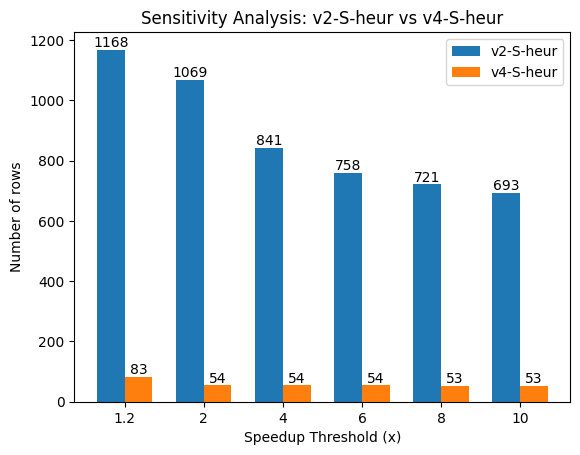

In [641]:
compare_speedups(df, "v2-S-heur", "v4-S-heur")